In [1]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.metrics import roc_auc_score, RocCurveDisplay
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer

import mlflow

# Paso 1: Carga y describe el dataset:

In [3]:
# Se carga el set de datos.
bank_data_df = pd.read_csv("bank-additional-full.csv", sep=";")
bank_data_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# Se ve su información general.
bank_data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

## 1.1 Estructura del set de datos
- __Descripción:__ El set de datos fue creado para crear un modelo que fuera capaz de predecir la probabilidad de que un cliente, de un banco portugués, contratara un deposito bancario a largo plazo, al ser contactado durante una campaña publicitaria actual de este. El modelo creado, a través de este set de datos, se utilizaría para ayudar a los gerentes, a cargo de la campaña publicitaria, a enfocar los esfuerzos de los agentes de ventas en los clientes que tengan la mayor posibilidad de contratar el depósito a largo plazo del banco. Esto ayudaría a utilizar mejor la mano de obra del banco y a obtener buenos resultados con menos llamadas.

- __Número de registros:__ 41188

| Variable       | Type    | Meaning |
|---------------|---------|---------|
| age           | int64   | La edad del cliente. |
| job           | str     | El tipo de empleo del cliente. |
| marital       | str     | El estado civil del cliente. |
| education     | str     | El máximo grado de estudios del cliente. |
| default       | str     | Si el cliente tiene un crédito en situación de impago. |
| housing       | str     | Si el cliente tiene un crédito hipotecario. |
| loan          | str     | Si el cliente tiene un crédito personal. |
| contact       | str     | El medio que se usó para contactar al cliente. |
| month         | str     | El último mes del año en el que fue contactado el cliente. |
| day_of_week   | str     | El último día de la semana en el que fue contactado el cliente. |
| duration      | int64   | La duración de la última llamada telefónica que se tuvo con el cliente. |
| campaign      | int64   | Número de veces a las que se a contactado el cliente en la campaña actual. |
| pdays         | int64   | Número de días que han pasado desde que se contactó al cliente en una campaña pasada. |
| previous      | int64   | Numero de veces que se ha contactado al cliente antes de la campaña actual. |
| poutcome      | str     | El resultado de la campaña anterior. |
| emp.var.rate  | float64 | Tasa de variación del empleo de Portugal __(Indicador trimestral)__ |
| cons.price.idx| float64 | Índice de precios del consumidor de Portugal __(Indicador mensual)__. |
| cons.conf.idx | float64 | Índice de confianza del consumidor de Portugal __(Indicador mensual)__. |
| euribor3m     | float64 | Tasa de interés interbancaria Euribor a tres meses __(Indicador diario)__. |
| nr.employed   | float64 | Numero de gente con empleo formal en Portugal __(Indicador trimestral)__. |
| y             | str     | Si el cliente contrató un depósito a largo plazo. |

# Paso 2: Realiza un análisis exploratorio (EDA):

## 2.1 Análisis de variables categóricas

In [5]:
# Se obtienen las variables categóricas del set de datos.
cat_vars = bank_data_df.select_dtypes(include=["str"])
cat_vars.head()

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent,no
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent,no
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent,no
3,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent,no
4,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent,no


In [6]:
# Se obtienen sus estadísticas descriptivas
cat_vars.describe().T

,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


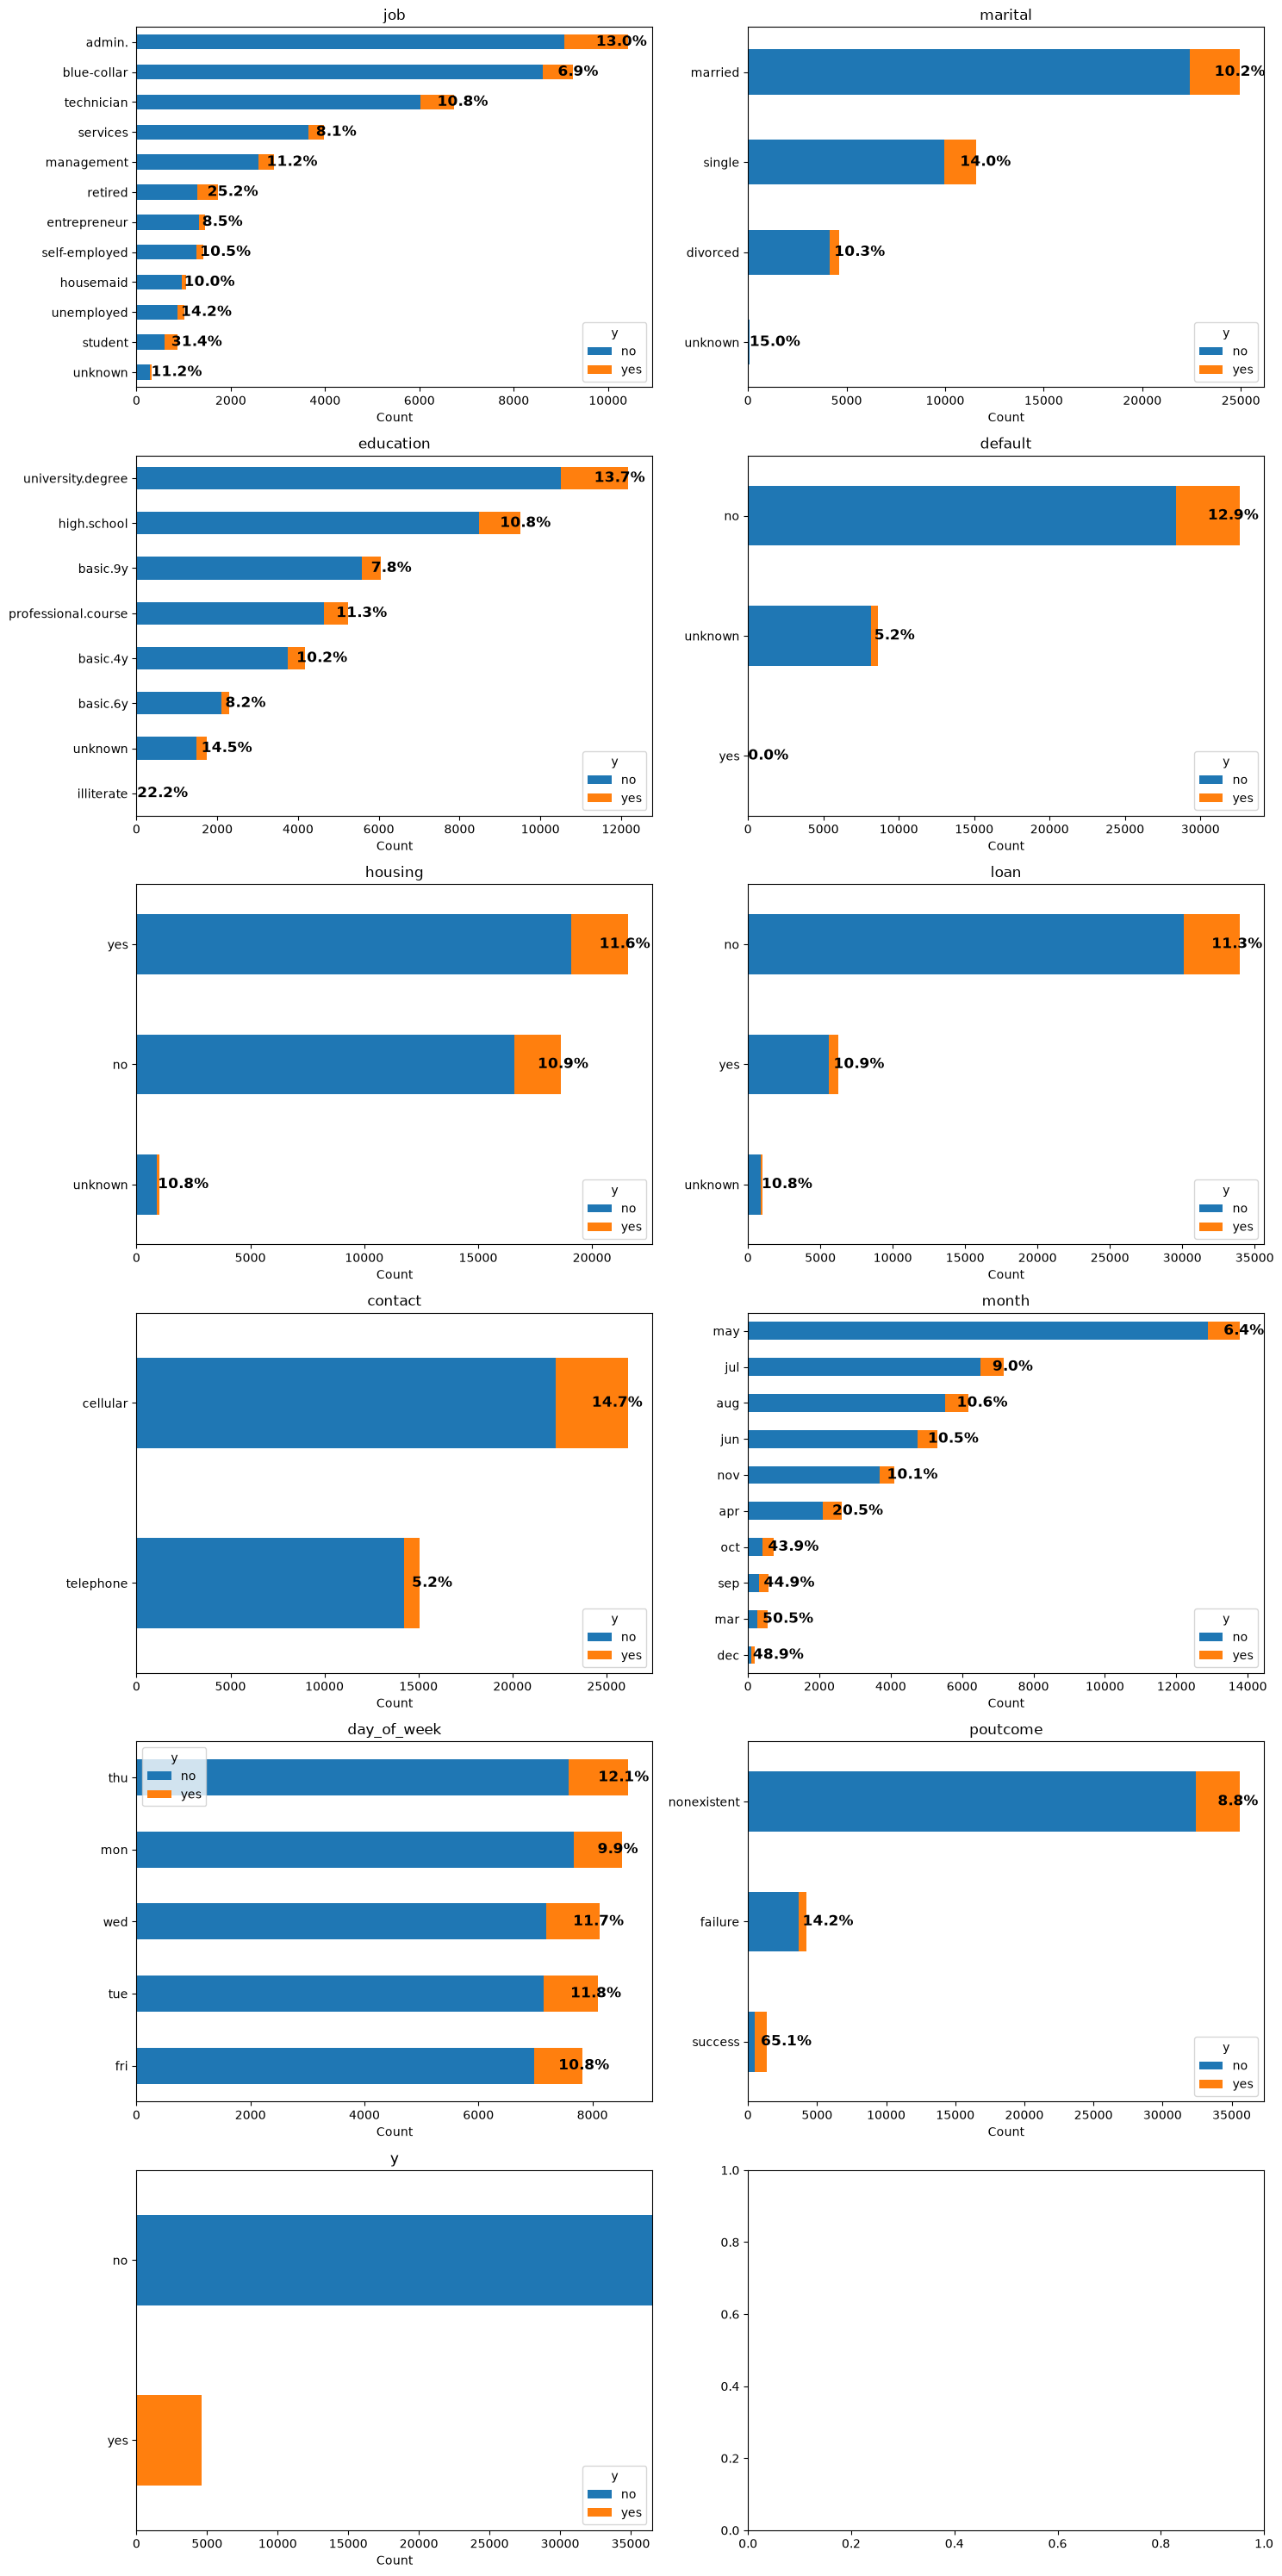

In [7]:
# Se crean gráficas de barras apiladas con las variables categóricas.
fig, axes = plt.subplots(6, 2, figsize=(15, 30))
axes = axes.flatten()

for ax, col in zip(axes, cat_vars):
    # Se crea una tabla de contingencia.
    contingency_table = (
        cat_vars
        .groupby([col, 'y'])
        .size()
        .unstack(fill_value=0)
    )

    # Se ordenan las categorias de las variables de texto de mayor a menor.
    contingency_table = contingency_table.loc[contingency_table.sum(axis=1).sort_values(ascending=True).index]

    # Se crea la grafica de barras.
    contingency_table.plot(
        kind='barh',
        stacked=True,
        ax=ax
    )

    if col != "y":
        proportions = contingency_table.div(contingency_table.sum(axis=1), axis=0)

        for i, (idx, row) in enumerate(contingency_table.iterrows()):
            prop_yes = proportions.loc[idx, "yes"] if "yes" in proportions.columns else 0

            count_no = row.get("no", 0)
            count_yes = row.get("yes", 0)
            
            x_pos = count_no + count_yes / 2

            ax.text(
                x_pos,
                i,
                f"{prop_yes:.1%}",
                va='center',
                ha='left',
                fontsize=12,
                fontweight='bold'
            )


    ax.set_title(col)
    ax.set_xlabel('Count')
    ax.set_ylabel('')
    ax.legend(title='y')

plt.tight_layout()
plt.show()

## 2.2 Hallazgos de las variables categóricas
- El set de datos esta desbalanceado, pues podemos ver, gracias a la variable “y”, que históricamente la mayoría de los clientes del banco no aceptan un depósito a largo plazo.
- En la variable “poutcome” podemos ver que el 65.1% de los clientes que contrataron un depósito a largo plazo, en una campaña publicitaria anterior, volvieron a contratar otro deposito durante la campaña actual.
- En la variable “contact” podemos ver que es mejor contactar a los clientes haciéndoles una llamada a su número celular que a su número telefónico, pues el 14.7% de los clientes que fueron contactados a su número celular contrataron el depósito bancario, mientras que solo el 5.2% de los clientes que fueron contactados a su número telefónico lo contrataron.

## 2.3 Análisis de variables numéricas

In [8]:
# Se obtienen las variables numéricas del set de datos.
num_vars = bank_data_df.select_dtypes(include=['int', "float"])
num_vars.head()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,56,261,1,999,0,1.1,93.994,-36.4,4.857,5191.0
1,57,149,1,999,0,1.1,93.994,-36.4,4.857,5191.0
2,37,226,1,999,0,1.1,93.994,-36.4,4.857,5191.0
3,40,151,1,999,0,1.1,93.994,-36.4,4.857,5191.0
4,56,307,1,999,0,1.1,93.994,-36.4,4.857,5191.0


In [9]:
# Se obtienen sus estadísticas descriptivas.
stats = num_vars.describe().T

stats["skew"] = num_vars.skew()
stats["kurtosis"] = num_vars.kurtosis()

stats

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000,0.784697,0.791312
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000,3.263141,20.247938
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000,4.762507,36.979795
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000,-4.922190,22.229463
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000,3.832042,20.108816
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400,-0.724096,-1.062632
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767,-0.230888,-0.829809
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900,0.303180,-0.358558
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045,-0.709188,-1.406803
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100,-1.044262,-0.003760


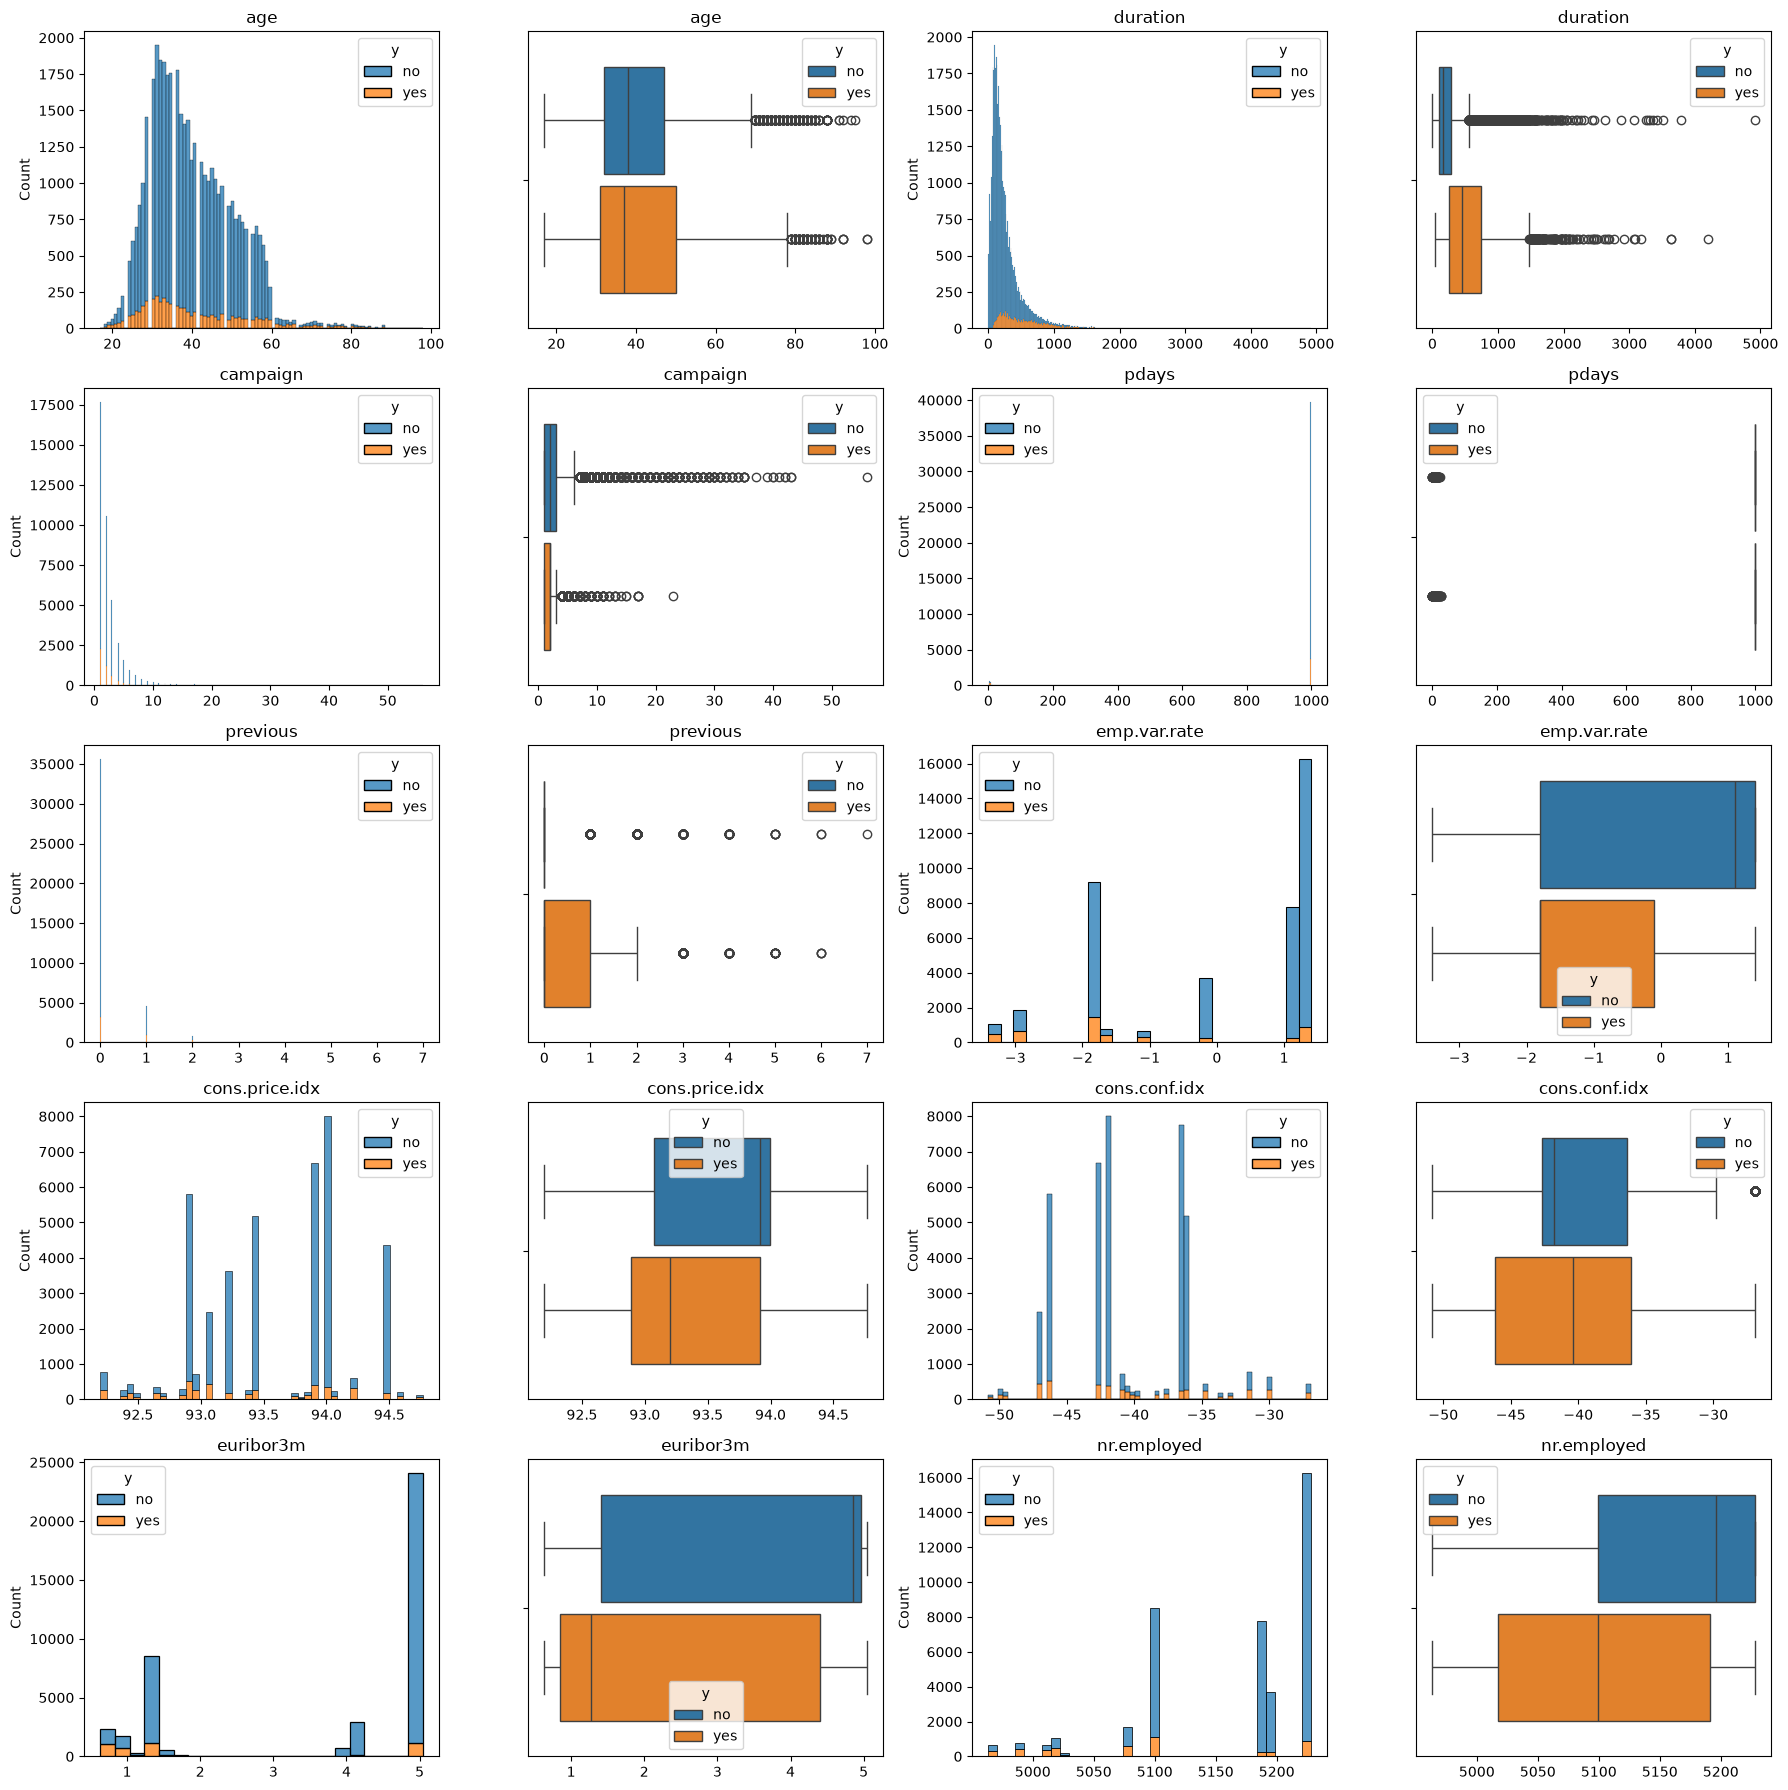

In [10]:
# Se crean histogramas y diagramas de caja y bigote para cada una de las variables numéricas.
fig, axes = plt.subplots(5, 4, figsize=(18, 18))
axes = axes.flatten()

counter = 0

# Por cada variable numérica haz lo siguiente.
for col in num_vars:

    histplot_ax = axes[0+counter]
    boxplot_ax = axes[1+counter]

    # Gráfica un histograma para saber la distribución de la variable.
    sns.histplot(
        data=bank_data_df,
        x=col,
        hue='y',
        hue_order=['no', 'yes'],
        multiple="stack",
        stat='count',
        ax=histplot_ax,
    )
    histplot_ax.set_title(col)
    histplot_ax.set_xlabel("")

    # Gráfica un diagrama de caja y bigote para ver si la distribución de la variable contiene valores atípicos.
    sns.boxplot(
        data=bank_data_df,
        x=col,
        hue='y',
        ax=boxplot_ax,
        gap=0.1
    )
    boxplot_ax.set_title(col)
    boxplot_ax.set_xlabel("")

    counter += 2

plt.tight_layout()
plt.show()

## 2.4 Hallazgos de las variables numéricas
- En la variable “duration” podemos ver que, entre más dure la última llamada que se le hizo a un cliente, mayores son las posibilidades de que contrate el depósito bancario. El único problema es que esta variable no se puede utilizar en el entrenamiento de un modelo, pues sus valores solo los podemos saber en el futuro, y no se pueden usar valores futuros que no se pueden obtener por ningún medio en el entrenamiento de nuestro modelo, por eso eliminaremos esta variable cuando limpiemos los datos.

# Paso 3: Limpia los datos:

In [11]:
# Se busca si hay valores nulos o faltantes en el set de datos.
bank_data_df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [12]:
# Se elimina la variable "duration" del set de datos y las variables numéricas.
bank_data_df = bank_data_df.drop(columns=["duration"])
num_vars = num_vars.drop(columns=["duration"])

bank_data_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  campaign        41188 non-null  int64  
 11  pdays           41188 non-null  int64  
 12  previous        41188 non-null  int64  
 13  poutcome        41188 non-null  str    
 14  emp.var.rate    41188 non-null  float64
 15  cons.price.idx  41188 non-null  float64
 16  cons.conf.idx   41188 non-null  float64
 17  euribor3m       41188 non-null  float64
 1

## Justificación
- El set de datos no cuenta con valores faltantes, por lo cual no se le tuvo que hacer ninguna transformación a los datos.
- La variable “duration” se tuvo que eliminar, porque no se puede usar una variable que solamente se pude saber en el futuro y no hay manera de predecir, pues la única manera de saber cuánto dura la última llamada que se le hizo a un cliente es cuando esta termina, por lo cual si el modelo quiere hacer una predicción no se le puede pasar este valor con anticipación.

# Paso 4: Entrena un modelo base:

In [13]:
# Se divide el set de datos en variables dependientes e independientes.
X = bank_data_df.drop(columns=["y"])
# Adicionalmente se transforman los valores de la variable dependiente en valores numéricos.
y = bank_data_df["y"].map({
'no': 0,
'yes': 1
})

# Se dividen los datos en conjuntos de prueba y entrenamiento.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [14]:
# Transformaciones para las variables numéricas sin sesgo.
numeric_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

# Transformaciones para las variables numéricas con sesgo.
numeric_skewed_pipeline = Pipeline([
    ('power', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

# Transformaciones para las variables categóricas.
cat_pipeline = Pipeline(
    steps=[
        ("ohe", OneHotEncoder(drop="first", sparse_output=False)),
    ]
)

# Variables que tienen un sesgo visible.
skewed_vars = ["campaign", "previous"]

# Transformador para aplicarle las transformaciones al set de datos de entrenamiento y prueba.
columnTransformer = ColumnTransformer(
    transformers=[
        ("numeric_pipeline", numeric_pipeline, num_vars.columns.drop(skewed_vars).to_list()),
        ("numeric_skewed_pipeline", numeric_skewed_pipeline, skewed_vars),
        ("cat_pipeline", cat_pipeline, cat_vars.columns.drop("y").to_list())
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

In [15]:
# Se le aplican las transformaciones al set de entrenamiento.
X_train_index = X_train.index
X_train = columnTransformer.fit_transform(X_train)

X_train = pd.DataFrame(data=X_train, index=X_train_index, columns=columnTransformer.get_feature_names_out())
X_train.head()

,age,pdays,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,campaign,previous,job_blue-collar,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
25611,0.863739,0.196584,-0.114858,-0.648967,-0.322269,0.288964,0.398990,1.189547,-0.399447,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
26010,-0.289722,0.196584,-0.114858,-0.648967,-0.322269,0.288964,0.398990,0.247568,2.502470,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
40194,3.651268,0.196584,-1.133161,1.103451,0.045048,-1.583296,-2.420139,-1.045395,-0.399447,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
297,-0.385843,0.196584,0.648868,0.721890,0.887717,0.713535,0.332723,0.247568,-0.399447,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
36344,1.824956,0.196584,-1.896888,-1.058152,-0.062987,-1.357472,-1.252175,0.247568,-0.399447,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [16]:
# Se le aplican las transformaciones al set de pruebas.
X_test_index = X_test.index
X_test = columnTransformer.transform(X_test)

X_test = pd.DataFrame(data=X_test, index=X_test_index, columns=columnTransformer.get_feature_names_out())
X_test.head()

,age,pdays,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,campaign,previous,job_blue-collar,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
14455,-0.770330,0.196584,0.839800,0.590675,-0.473517,0.773448,0.844915,1.407698,-0.399447,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
36380,-0.289722,0.196584,-1.896888,-1.058152,-0.062987,-1.357472,-1.252175,-1.045395,-0.399447,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
40076,3.170659,0.196584,-1.133161,1.103451,0.045048,-1.617860,-2.420139,0.247568,-0.399447,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
10778,0.383130,0.196584,0.839800,1.535081,-0.279055,0.773448,0.844915,0.247568,-0.399447,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
27939,-1.154817,0.196584,-1.196805,-1.265334,-2.050821,-1.202507,-0.936023,0.247568,-0.399447,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [17]:
# Se verifica que las transformaciones se aplicaran de manera correcta.
x_train_stats = X_train.describe().T

x_train_stats["skew"] = X_train.skew()
x_train_stats["kurtosis"] = X_train.kurtosis()

x_train_stats

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
age,32950.0,2.505768e-16,1.000015,-2.212156,-0.770330,-0.193600,0.671495,5.573702,0.760819,0.672276
pdays,32950.0,-1.938628e-16,1.000015,-5.118709,0.196584,0.196584,0.196584,0.196584,-4.890610,21.919840
emp.var.rate,32950.0,-4.097212e-17,1.000015,-2.215107,-1.196805,0.648868,0.839800,0.839800,-0.721077,-1.067286
cons.price.idx,32950.0,8.406184e-15,1.000015,-2.373760,-0.864782,0.298893,0.721890,2.056490,-0.231165,-0.831579
cons.conf.idx,32950.0,1.872641e-15,1.000015,-2.223676,-0.473517,-0.279055,0.887717,2.940371,0.305846,-0.354241
euribor3m,32950.0,-5.175425e-18,1.000015,-1.719251,-1.310234,0.713535,0.773448,0.821838,-0.705554,-1.412340
nr.employed,32950.0,5.998318e-15,1.000015,-2.806699,-0.936023,0.332723,0.844915,0.844915,-1.043085,-0.008286
campaign,32950.0,-3.277769e-17,1.000015,-1.045395,-1.045395,0.247568,0.848104,2.234623,0.268098,-1.305526
previous,32950.0,2.005477e-17,1.000015,-0.399447,-0.399447,-0.399447,-0.399447,2.507776,2.104112,2.427437
job_blue-collar,32950.0,2.258270e-01,0.418132,0.000000,0.000000,0.000000,0.000000,1.000000,1.311498,-0.279991


In [18]:
# Se entrena el modelo base.
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

# Se obtienen las probabilidades de que la clase sea positiva.
y_prob = model.predict_proba(X_test)[:, 1]

## Justificación de elección del modelo base:
Se decidió usar un modelo de regresión logística como modelo base, pues este es posiblemente el modelo más sencillo que existe para resolver un problema de clasificación binaria. Se usaron los parámetros que el modelo usa por defecto, pues la idea es que este modelo sirva como referencia para evaluar futuros modelos.

# Paso 5: Evalúa el modelo:

## Curva ROC-AUC

AUC: 0.8011


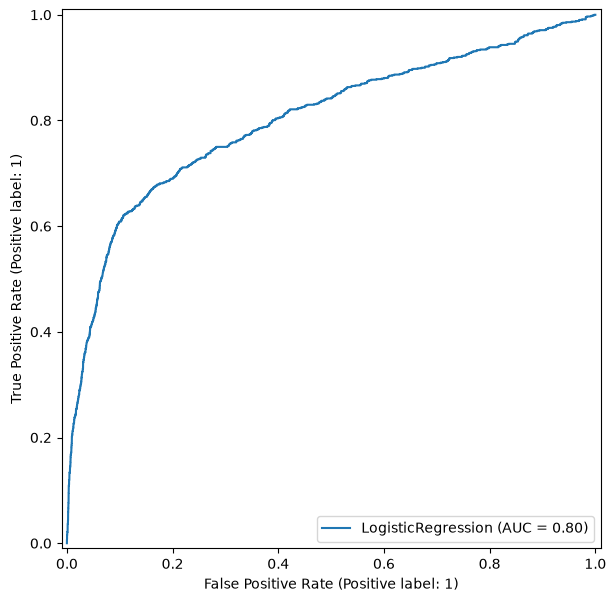

In [19]:
# Se calcula la curva ROC AUC.
auc = roc_auc_score(y_test, y_prob)

# Se muestran los resultados de la evaluación.
print(f"AUC: {auc:.4f}")

fig_roc_curve, ax = plt.subplots(figsize=(7, 7))

RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax)
plt.show()

## Curva LIFT cumulativa

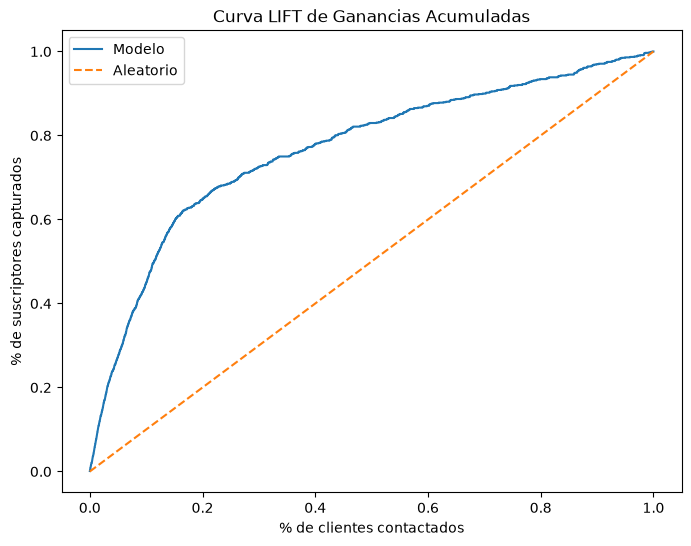

In [20]:
# Crear DataFrame con valores reales y probabilidades.
lift_df = pd.DataFrame({
    "actual": y_test,
    "prob": y_prob
})

# Ordenar de mayor a menor probabilidad.
lift_df = lift_df.sort_values(
    "prob",
    ascending=False
)

# Calcular positivos acumulados.
lift_df["cum_positive"] = lift_df["actual"].cumsum()

# Obtener total de positivos.
total_positive = lift_df["actual"].sum()

# Calcular ganancia acumulada.
lift_df["gain"] = lift_df["cum_positive"] / total_positive

# Calcular porcentaje de clientes contactados
lift_df["customers"] = np.arange(
    1,
    len(lift_df) + 1
) / len(lift_df)

# Crear figura
fig_lift_curve, ax = plt.subplots(figsize=(8,6))

# Graficar curva del modelo
ax.plot(
    lift_df["customers"],
    lift_df["gain"],
    label="Modelo"
)

# Graficar línea de selección aleatoria
ax.plot(
    [0,1],
    [0,1],
    "--",
    label="Aleatorio"
)

# Etiquetas de ejes
ax.set_xlabel("% de clientes contactados")
ax.set_ylabel("% de suscriptores capturados")

# Título y leyenda
ax.set_title("Curva LIFT de Ganancias Acumuladas")
ax.legend()

# Mostrar gráfica
plt.show()

## Justificación sobre las métricas escogidas:
- Se decidió escoger la métrica de ROC-AUC, para poder ver a simple vista que tan bien discrimina el modelo las dos clases utilizando diferentes límites. Su gráfica nos puede ayudar a seleccionar un límite en específico, dependiendo de que tantos verdaderos y falsos positivos estamos dispuestos a aceptar. La gráfica también nos servirá en le futuro, para comparar fácilmente múltiples modelos con el modelo base, pues se pueden graficar sus curvas ROC-AUC junto con la del modelo base.

- También se utilizó la métrica LIFT cumulativa pues, en el estudio original del conjunto de datos, se busca crear un modelo que ayude a maximizar la cantidad de clientes que contraten exitosamente el depósito bancario realizando la menor cantidad de llamadas posible. La curva LIFT cumulativa mide qué tan superior es la estrategia de selección del modelo respecto a una selección aleatoria, mostrando cuántos clientes potencialmente interesados pueden identificarse al contactar primero a aquellos que el modelo considera más propensos a aceptar la oferta. De esta manera, la curva nos permite visualizar fácilmente la proporción de clientes que contratarían el depósito bancario en función de la cantidad de llamadas que estamos dispuestos a realizar, facilitando la evaluación del beneficio práctico y comercial del modelo.


# Paso 6: Registra el experimento en MLFlow:

In [21]:
# Configuración de MLFlow
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("Bank long-term deposit telemarketing campaign")

sample_sizes = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

with mlflow.start_run():

    mlflow.set_tag("Training Info", "Base model")

    # Se guarda el modelo y sus hiperparametros.
    mlflow.log_params(model.get_params())
    mlflow.sklearn.log_model(
        model,
        artifact_path="logistic_regression"
    )

    # Se guarda la métrica de ROC-AUC y la imagen de su curva.
    mlflow.log_metric("roc_auc", auc)
    mlflow.log_figure(fig_roc_curve, "roc_curve.png")

    # Se guarda la imagen de la curva LIFT cumulativa, 
    # y varias métricas de subscriptores capturados 
    # dependiendo del porcentaje de clientes contactados.
    for size in sample_sizes:
        gain_size = lift_df.loc[
        lift_df["customers"] <= size,
        "gain"
        ].iloc[-1]

        mlflow.log_metric(f"capture_rate_top_{int(size * 100)}pct", gain_size)
    
    mlflow.log_figure(fig_lift_curve, "lift_curve.png")

2026/10/04 11:21:00 INFO mlflow.tracking.fluent: Experiment with name 'Bank long-term deposit telemarketing campaign' does not exist. Creating a new experiment.
2026/10/04 11:21:00 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run blushing-gnu-520 at: http://localhost:5000/#/experiments/1/runs/9391c3f9aed84475ab8d1fdbfe317796
🧪 View experiment at: http://localhost:5000/#/experiments/1


## Evidencia de MLFlow

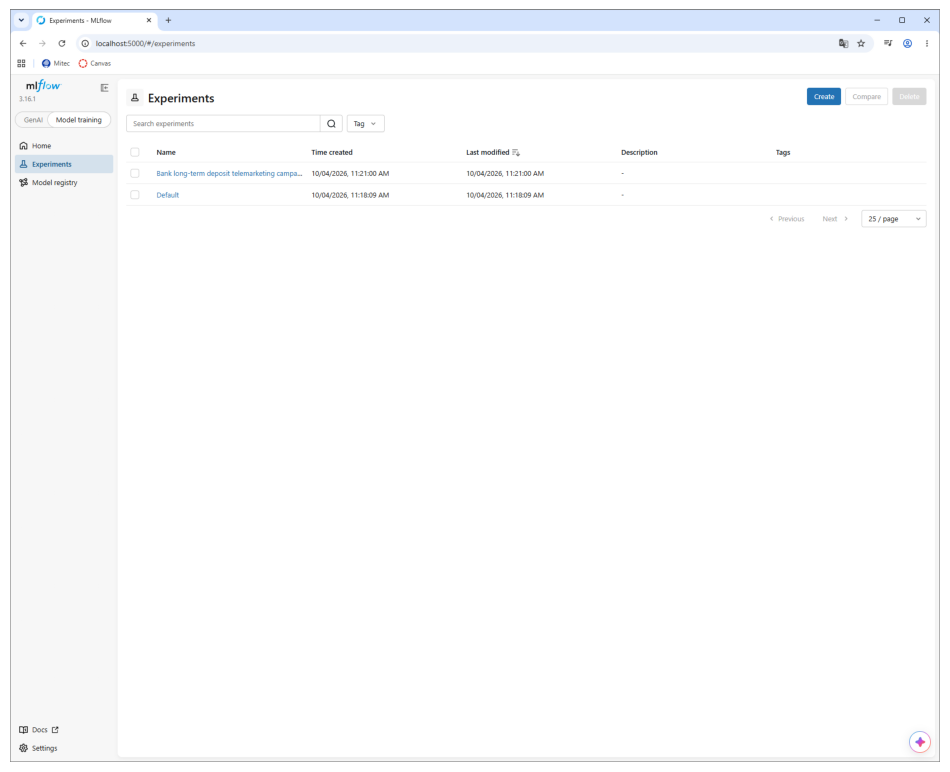

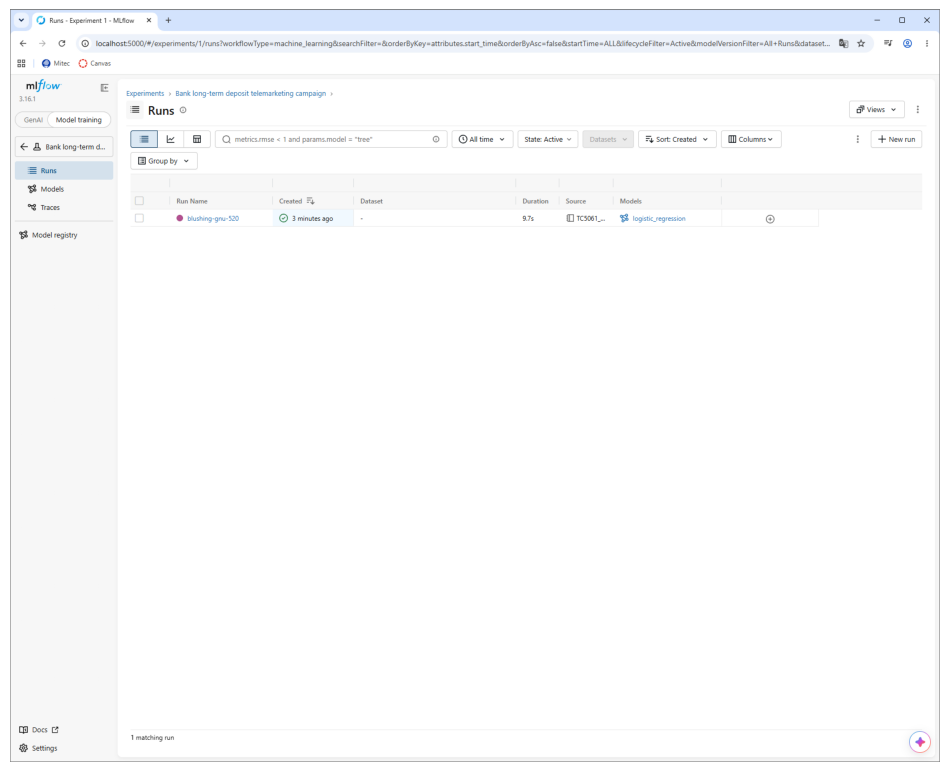

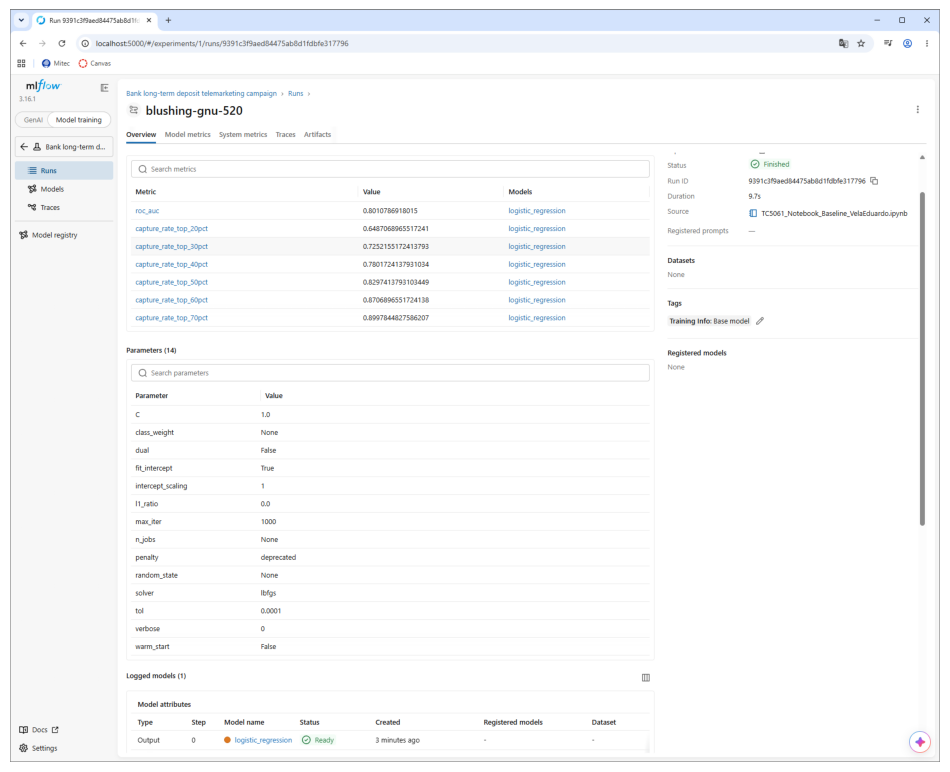

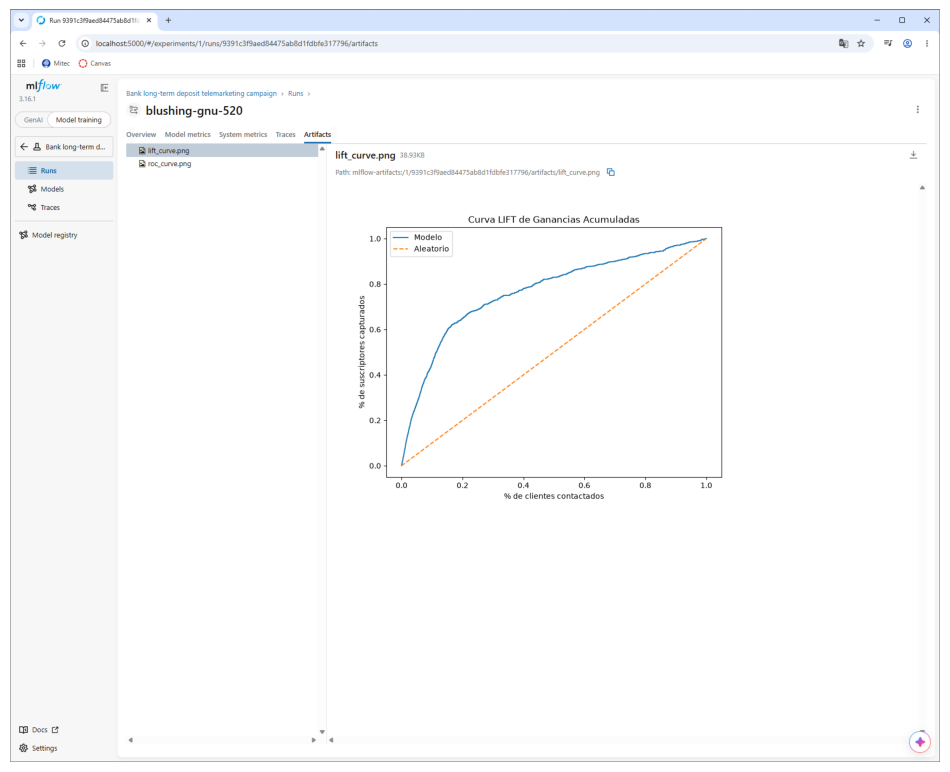

In [4]:
for i in range(4):
    img = mpimg.imread(f"mlflow-{i+1}.png")

    plt.figure(figsize=(12, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

# Paso 7: Redacta una reflexión:

- ¿Qué mejorarías del flujo de esta actividad?

Lo que yo mejoraría, del flujo de esta actividad, sería registrar las características del set de datos que se usó para entrenar el modelo base, pues en esta actividad se registraron los parámetros, métricas, y artefactos del modelo, pero nunca se registro el set de datos que se utilizó para entrenarlo. Lo ideal guardar el set de datos en un lugar centralizado, como en un contenedor de Azure, para que yo y mis compañeros podemos usar exactamente el mismo set de datos en futuros experimentos, lo cual evita que alguien use accidentalmente un set de datos equivocado, comprometiendo los resultados de sus experimentos. Además, es importante documentar las transformaciones que se le hicieron al set de datos, ya sea para limpiarlo o añadirle características.
También creo que es importante documentar las transformaciones que se le hicieron a los datos, para que el modelo los procesara, pues esto ayudaría a reproducir mis experimentos, ya que mis compañeros tendrían el conocimiento de como transforme las variables categóricas y numéricas, para que el modelo las pudiera usar.

- ¿Cómo se ven reflejados estos aprendizajes dentro de tu área profesional?

Si no se tienen documentadas y ordenadas las cosas es muy fácil perderse, pues se te pueden olvidar los hiperparametros que utilizaste para entrenar un modelo, donde guardaste dentro de tu computadora un set de datos que no subiste a Azure y ahora tienes que volver a encontrar, las transformaciones que le aplicaste a los datos que usa el modelo y el porqué de estas. MLOPS ayuda que perdamos menos tiempo e información valiosa en el proceso de experimentación, y con esto ayuda a contener el caos que puede ser causado por un ambiente de trabajo desorganizado. Además, fomenta que nuestros experimentos sean reproducibles y se puedan recrear en cualquier momento de manera fácil.


# Referencias:
-  Moro, S., Rita, P., & Cortez, P. (2014). Bank Marketing [Dataset]. UCI Machine Learning Repository. [https://doi.org/10.24432/C5K306](https://doi.org/10.24432/C5K306).
-   [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, In press, [http://dx.doi.org/10.1016/j.dss.2014.03.001](http://dx.doi.org/10.1016/j.dss.2014.03.001)
